# 02 · Fine-mapping and colocalization with SVs and SNVs

*Prepared by Junyoung Park ([jpark01@stanford.edu](mailto:jpark01@stanford.edu)). Analysis code adapted from [tjense25/ADRC-Flagship-lrGS-Code](https://github.com/tjense25/ADRC-Flagship-lrGS-Code) by Tanner D. Jensen (MIT License).*

We go through the analysis step by step:

1. **SV-QTL scan**: test every common SV within 1 Mb of a molecular trait.
2. **Joint SV + SNV fine-mapping** with SuSiE: which variants are in the credible set, and is an SV
   the lead variant?
3. **Colocalization** of the molecular trait with AD or PD GWAS (`coloc.abf`).
4. **Put it together**: an SV is a candidate disease variant when the trait colocalizes with the GWAS
   *and* the SV is in the trait's credible set.

Three loci from the paper:

| Locus | Molecular trait | SV highlighted in the paper | Disease GWAS |
|---|---|---|---|
| HP | HP protein, plasma and CSF | 1.7 kb deletion spanning two exons | none (fine-mapping example) |
| GGA2 / COG7 | methylation segment chr16:23,504,004-23,505,148 | 208 bp tandem-repeat deletion near the COG7 promoter | Alzheimer's disease |
| MAPT / KANSL1 / LRRC37A2 | LRRC37A2 expression in PBMC | 37 bp insertion | Alzheimer's and Parkinson's disease |

In [1]:
# On Google Colab (Runtime > Change runtime type > R) this first downloads the workshop files.
if (!file.exists("../R/setup.R") && !file.exists("R/setup.R")) {
    if (!dir.exists("sv-finemapping-coloc-tutorial"))
        system("git clone --depth 1 https://github.com/Junkkkk/sv-finemapping-coloc-tutorial.git")
    if (!dir.exists("sv-finemapping-coloc-tutorial/notebooks"))
        stop("Could not download the workshop files from GitHub. Check the internet connection.")
    setwd("sv-finemapping-coloc-tutorial/notebooks")
}
source(if (file.exists("../R/setup.R")) "../R/setup.R" else "R/setup.R")
LOCI

locus,chrom,region_start,region_end,layer,pheno_id,label,sv_id,gwas,gwas_lead_pos
<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>
HP,chr16,71054505,73058850,Plasma,ENSG00000257017:HP.3054.3.2,"HP protein (plasma, aptamer 3054-3)",Sniffles2.DEL.14B0MF,,NA
HP,chr16,71054505,73058850,Plasma,ENSG00000257017:HP.7905.30.3,"HP protein (plasma, aptamer 7905-30)",Sniffles2.DEL.14B0MF,,NA
HP,chr16,71054505,73058850,CSF,HP.3054.3.2:ENSG00000257017:HP,"HP protein (CSF, aptamer 3054-3)",Sniffles2.DEL.14B0MF,,NA
HP,chr16,71054505,73058850,CSF,HP.7905.30.3:ENSG00000257017:HP,"HP protein (CSF, aptamer 7905-30)",Sniffles2.DEL.14B0MF,,NA
COG7,chr16,22462828,24505148,Methylation,chr16_10_113,Methylation segment near GGA2/COG7,Sniffles2.DEL.8FEMF,AD,23466676
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,AD,46613342
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,AD,46720553
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,PD,46276519
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,PD,46783637


## Settings

In [2]:
N_PCS <- c(Plasma = 40, CSF = 30, RNA = 30, Methylation = 7)   # number of phenotype PCs used as covariates
CIS_WINDOW <- 1e6                                              # SNVs/SVs within 1 Mb of the trait
COLOC_HALF_WINDOW <- 5e5                                       # colocalization window: GWAS lead ±500 kb
GWAS_N <- c(AD = 487511, PD = 611485)                          # GWAS sample sizes
GWAS_CASE_FRACTION <- 0.15
QTL_N <- c(Plasma = 423, CSF = 184, RNA = 235, Methylation = 423)  # QTL sample sizes used in coloc

## Load the data

Each locus has an SV genotype file (544 people), an SNV/indel genotype file (416 people with
short-read genomes), and the molecular trait values. All Twin values are continuous numbers, including
genotype dosages; use them as numeric values.

In [3]:
load_layer <- function(layer) {
    ph <- fread(file.path(DATA_DIR, "phenotypes", paste0(layer, ".phenotypes.tsv")))
    cv <- fread(file.path(DATA_DIR, "covariates", paste0(layer, ".covariates.tsv.gz")))
    mat <- as.matrix(ph[, 5:ncol(ph)], rownames.value = ph$pheno_id)
    covars <- as.matrix(cv[, -1], rownames.value = cv$ID)
    stopifnot(identical(colnames(mat), rownames(covars)))
    list(info = ph[, 1:4], mat = mat, covars = covars)
}
layers <- setNames(lapply(unique(LOCI$layer), load_layer), unique(LOCI$layer))
geno <- lapply(setNames(unique(LOCI$locus), unique(LOCI$locus)), function(l) list(
    SV = read_genotypes(file.path(DATA_DIR, "genotypes", paste0(l, ".SV.tsv.gz"))),
    SNV = read_genotypes(file.path(DATA_DIR, "genotypes", paste0(l, ".SNV.tsv.gz")))))
sapply(layers, function(x) c(people = ncol(x$mat), traits = nrow(x$mat), covariate_columns = ncol(x$covars)))
sapply(geno, function(x) c(SVs = nrow(x$SV$mat), SNVs = nrow(x$SNV$mat),
                           people_SV = ncol(x$SV$mat), people_SNV = ncol(x$SNV$mat)))

,Plasma,CSF,Methylation,RNA
people,490,225,544,268
traits,2,2,1,1
covariate_columns,134,109,94,134


,HP,COG7,MAPT
SVs,30,73,84
SNVs,3854,4551,8361
people_SV,544,544,544
people_SNV,416,416,416


## Step 1 · SV-QTL scan

For one trait, every SV whose interval overlaps the trait position ±1 Mb is tested with a linear
model `trait ~ SV dosage + covariates`. The paper then applies Benjamini-Hochberg across all
SV-trait pairs genome-wide; here we only look at the tests near our traits.

In [4]:
qtl_map <- function(vp_pair, genos.mat, phenos.mat, covars) {
    GT = genos.mat[vp_pair[["vid"]], ]
    Pheno = phenos.mat[vp_pair[["pid"]], ]
    Pheno = Pheno[!is.na(GT)]
    X = as.matrix(cbind(GT = genos.mat[vp_pair[["vid"]], ], covars))
    X = X[!is.na(GT), ]
    lm_result <- fastLmPure(X, y = Pheno)
    lm_result$pvalue <- pt(abs(lm_result$coefficients / lm_result$se), df = (nrow(X) - ncol(X)), lower.tail = F)
    data.frame(pid = vp_pair[["pid"]], vid = vp_pair[["vid"]], beta = lm_result$coefficients[1],
               SE = lm_result$se[1], p_val = lm_result$pvalue[1])
}

sv_qtl_scan <- function(locus, layer, this_pheno) {
    L <- layers[[layer]]
    covars <- L$covars[, 1:(14 + N_PCS[[layer]])]
    sv <- geno[[locus]]$SV
    pos <- L$info[pheno_id == this_pheno]
    in_window <- sv$info$start <= pos$end + CIS_WINDOW & sv$info$end >= pos$start - CIS_WINDOW
    genos.mat <- sv$mat[in_window, rownames(covars), drop = FALSE]
    pairs <- data.frame(pid = this_pheno, vid = rownames(genos.mat))
    res <- rbindlist(lapply(seq_len(nrow(pairs)), function(i) qtl_map(pairs[i, ], genos.mat, L$mat, covars)))
    res <- merge(sv$info[, .(vid = variant_id, start, end, svlen)], res, by = "vid")
    res[order(p_val)]
}

traits <- unique(LOCI[, .(locus, layer, pheno_id, label, sv_id)])
scans <- list()
for (i in seq_len(nrow(traits))) {
    a <- traits[i]
    s <- sv_qtl_scan(a$locus, a$layer, a$pheno_id)
    scans[[a$pheno_id]] <- s
    cat(sprintf("\n%s  (%s, %d people, %d SVs tested)\n", a$label, a$layer, ncol(layers[[a$layer]]$mat), nrow(s)))
    print(head(s[, .(vid, start, svlen, beta = signif(beta, 3), p_val = signif(p_val, 3),
                     paper_SV = vid == a$sv_id)], 3))
}


HP protein (plasma, aptamer 3054-3)  (Plasma, 490 people, 30 SVs tested)
                    vid    start svlen  beta    p_val paper_SV
1: Sniffles2.DEL.14B0MF 72057133 -1717 0.930 3.64e-71     TRUE
2: Sniffles2.DEL.14AEMF 72040474  -111 0.785 4.72e-07    FALSE
3: Sniffles2.DEL.14A0MF 71832246   -35 0.358 2.05e-05    FALSE

HP protein (plasma, aptamer 7905-30)  (Plasma, 490 people, 30 SVs tested)
                    vid    start svlen  beta    p_val paper_SV
1: Sniffles2.DEL.14B0MF 72057133 -1717 0.879 5.26e-64     TRUE
2: Sniffles2.DEL.14AEMF 72040474  -111 0.752 9.06e-07    FALSE
3: Sniffles2.DEL.14A0MF 71832246   -35 0.352 2.03e-05    FALSE

HP protein (CSF, aptamer 3054-3)  (CSF, 225 people, 30 SVs tested)
                    vid    start svlen   beta    p_val paper_SV
1: Sniffles2.DEL.14B0MF 72057133 -1717  0.860 1.06e-41     TRUE
2: Sniffles2.DEL.14AEMF 72040474  -111  0.794 1.79e-05    FALSE
3: Sniffles2.INS.148AMF 71382140    34 -0.306 3.46e-04    FALSE

HP protein (CSF, aptam

## Step 2 · Joint SV + SNV fine-mapping

For each trait the code

1. takes the people who have SV genotypes, SNV genotypes and the trait,
2. puts all SNVs/indels and SVs within ±1 Mb into one genotype matrix `X` (SVs placed at their
   midpoint) and scales it,
3. regresses the covariates out of the trait and scales the residual `Y`,
4. runs `susie(X, Y, L = 10, min_abs_corr = 0.25)`.

SuSiE in four lines:

* It assumes up to `L` (here 10) separate causal signals in the region.
* For each signal it reports a **credible set**: a small group of variants that contains the causal
  variant with 95% probability.
* The **PIP** (posterior inclusion probability) of a variant is the probability that it is causal for one
  of the signals.
* **Purity** is the smallest absolute correlation between variants of a credible set; sets with purity
  below `min_abs_corr = 0.25` are dropped because they do not point to one signal.

In [5]:
finemap_pheno <- function(locus, layer, this_pheno, L = 10) {
    lay <- layers[[layer]]
    snv <- geno[[locus]]$SNV
    sv <- geno[[locus]]$SV
    matched_samples <- colnames(snv$mat)
    matched_samples <- matched_samples[matched_samples %in% colnames(lay$mat)]
    matched_samples <- matched_samples[matched_samples %in% colnames(sv$mat)]
    covariates <- lay$covars[matched_samples, 1:(14 + N_PCS[[layer]])]

    pos <- lay$info[pheno_id == this_pheno]
    lo <- max(0, pos$start - CIS_WINDOW); hi <- pos$end + CIS_WINDOW
    snp_matrix <- t(snv$mat[snv$info$pos >= lo & snv$info$pos <= hi, matched_samples])
    cis_sv <- sv$info$start <= hi & sv$info$end >= lo
    cis_sv_matrix <- t(sv$mat[cis_sv, matched_samples])
    mid_point_df <- data.frame(midpoint = round((sv$info$start + sv$info$end) / 2), variant_id = sv$info$variant_id)

    merged_matrix <- cbind(snp_matrix, cis_sv_matrix)
    col_variances <- apply(merged_matrix, 2, var, na.rm = T)
    merged_matrix <- merged_matrix[, col_variances > 1e-8]
    starts <- as.numeric(ifelse(grepl(colnames(merged_matrix), pattern = "Sniffles2"),
                                yes = mid_point_df$midpoint[match(colnames(merged_matrix), mid_point_df$variant_id)],
                                no = gsub(colnames(merged_matrix), pattern = "\\w+:(\\d+):.+", replacement = "\\1")))
    merged_matrix <- merged_matrix[, order(starts)]

    X <- scale(merged_matrix)
    Y <- lay$mat[this_pheno, matched_samples]
    fit <- lm.fit(y = Y, x = covariates)
    Y.residualized <- scale(resid(fit))

    get_pvalue <- function(X, Y) {
        X <- as.matrix(X)
        fit <- fastLmPure(X, Y)
        return(pt(abs(fit$coefficients / fit$se), df = nrow(X) - 1, lower.tail = F))
    }
    pvalues <- sapply(1:ncol(X), function(i) get_pvalue(X[, i], Y.residualized))
    set.seed(1)   # susie() samples variants to compute the purity of credible sets with > 100 variants
    fitted <- suppressMessages(susie(X, Y.residualized, L = L, min_abs_corr = .25))
    out <- data.table(start = starts[order(starts)], pvalue = pvalues, var_id = colnames(X), pip = fitted$pip,
                      var_type = ifelse(grepl(x = colnames(X), "Sniffles2"), yes = "SV", no = "SNP"),
                      pheno = this_pheno, credible_set = NA_character_)
    if (length(fitted$sets$cs_index) > 0) {
        for (i in 1:length(fitted$sets$cs_index)) {
            out$credible_set[fitted$sets$cs[[i]]] <- paste0("L", fitted$sets$cs_index[i])
        }
    }
    list(X = X, Y = Y.residualized, susie = fitted, vardata = out, n = length(matched_samples))
}

Run it for the four HP aptamer-tissue pairs, the COG7 methylation segment and LRRC37A2 expression.

In [6]:
fits <- list()
for (i in seq_len(nrow(traits))) {
    a <- traits[i]
    t0 <- Sys.time()
    fits[[a$pheno_id]] <- finemap_pheno(a$locus, a$layer, a$pheno_id)
    cat(sprintf("%-40s n = %d, %d variants, %.0f s\n", a$label, fits[[a$pheno_id]]$n,
                nrow(fits[[a$pheno_id]]$vardata), as.numeric(Sys.time() - t0, units = "secs")))
}

HP protein (plasma, aptamer 3054-3)      n = 416, 3873 variants, 2 s
HP protein (plasma, aptamer 7905-30)     n = 416, 3873 variants, 2 s
HP protein (CSF, aptamer 3054-3)         n = 183, 3873 variants, 1 s
HP protein (CSF, aptamer 7905-30)        n = 183, 3873 variants, 1 s
Methylation segment near GGA2/COG7       n = 416, 4619 variants, 2 s
LRRC37A2 expression (PBMC)               n = 230, 7074 variants, 2 s


### Credible sets

For each credible set: its size, its purity (smallest |correlation| between its variants), the lead
variant (highest PIP), and whether it contains an SV. This is how the paper labels each QTL:
"SV in credible set" and "SV is the lead variant".

In [7]:
cs_summary <- function(fit, label) {
    v <- fit$vardata
    if (all(is.na(v$credible_set))) return(data.table(trait = label, cs = "none"))
    pur <- fit$susie$sets$purity
    rbindlist(lapply(sort(unique(na.omit(v$credible_set))), function(cs) {
        s <- v[credible_set == cs]
        lead <- s[which.max(pip)]
        data.table(trait = label, cs = cs, size = nrow(s),
                   purity = round(pur[cs, "min.abs.corr"], 3),
                   lead_variant = lead$var_id, lead_pip = round(lead$pip, 3),
                   SVs_in_cs = paste(s[var_type == "SV", var_id], collapse = "; "),
                   SV_is_lead = lead$var_type == "SV")
    }))
}
cs_table <- rbindlist(lapply(seq_len(nrow(traits)), function(i)
    cs_summary(fits[[traits$pheno_id[i]]], traits$label[i])), fill = TRUE)
cs_table

trait,cs,size,purity,lead_variant,lead_pip,SVs_in_cs,SV_is_lead
<chr>,<chr>,<int>,<dbl>,<chr>,<dbl>,<chr>,<lgl>
"HP protein (plasma, aptamer 3054-3)",L1,1,1.000,Sniffles2.DEL.14B0MF,1.000,Sniffles2.DEL.14B0MF,TRUE
"HP protein (plasma, aptamer 7905-30)",L1,1,1.000,Sniffles2.DEL.14B0MF,1.000,Sniffles2.DEL.14B0MF,TRUE
"HP protein (CSF, aptamer 3054-3)",L1,1,1.000,Sniffles2.DEL.14B0MF,1.000,Sniffles2.DEL.14B0MF,TRUE
"HP protein (CSF, aptamer 7905-30)",L1,1,1.000,Sniffles2.DEL.14B0MF,1.000,Sniffles2.DEL.14B0MF,TRUE
Methylation segment near GGA2/COG7,L1,57,0.908,16:23493672:C:T,0.063,Sniffles2.DEL.8FEMF,FALSE
LRRC37A2 expression (PBMC),L1,2656,0.885,Sniffles2.INS.1142M10,0.017,Sniffles2.DEL.113AM10; Sniffles2.INS.1141M10; Sniffles2.INS.1142M10; Sniffles2.DEL.1149M10; Sniffles2.DEL.116FM10,TRUE


### Look at the paper's SVs

In [8]:
paper_sv <- rbindlist(lapply(seq_len(nrow(traits)), function(i) {
    a <- traits[i]; v <- fits[[a$pheno_id]]$vardata
    s <- v[var_id == a$sv_id]
    top_snv <- v[var_type == "SNP"][which.min(pvalue)]
    data.table(trait = a$label, SV = a$sv_id, SV_p = signif(s$pvalue, 3), SV_pip = round(s$pip, 4),
               SV_credible_set = s$credible_set, best_SNV = top_snv$var_id, best_SNV_p = signif(top_snv$pvalue, 3))
}))
paper_sv

trait,SV,SV_p,SV_pip,SV_credible_set,best_SNV,best_SNV_p
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>
"HP protein (plasma, aptamer 3054-3)",Sniffles2.DEL.14B0MF,1.37e-53,1.0000,L1,16:72072066:C:T,9.29e-22
"HP protein (plasma, aptamer 7905-30)",Sniffles2.DEL.14B0MF,1.84e-48,1.0000,L1,16:72072066:C:T,3.96e-20
"HP protein (CSF, aptamer 3054-3)",Sniffles2.DEL.14B0MF,1.73e-29,1.0000,L1,16:72080103:T:C,2.94e-15
"HP protein (CSF, aptamer 7905-30)",Sniffles2.DEL.14B0MF,4.80e-28,1.0000,L1,16:72080103:T:C,1.55e-15
Methylation segment near GGA2/COG7,Sniffles2.DEL.8FEMF,4.38e-11,0.0551,L1,16:23478208:A:G,3.47e-11
LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,4.18e-24,0.0174,L1,17:46417942:G:A,5.19e-24


### Plot: marginal association and PIP

Top: −log10 p of every variant (SVs as large triangles). Bottom: SuSiE PIP, coloured by credible set.

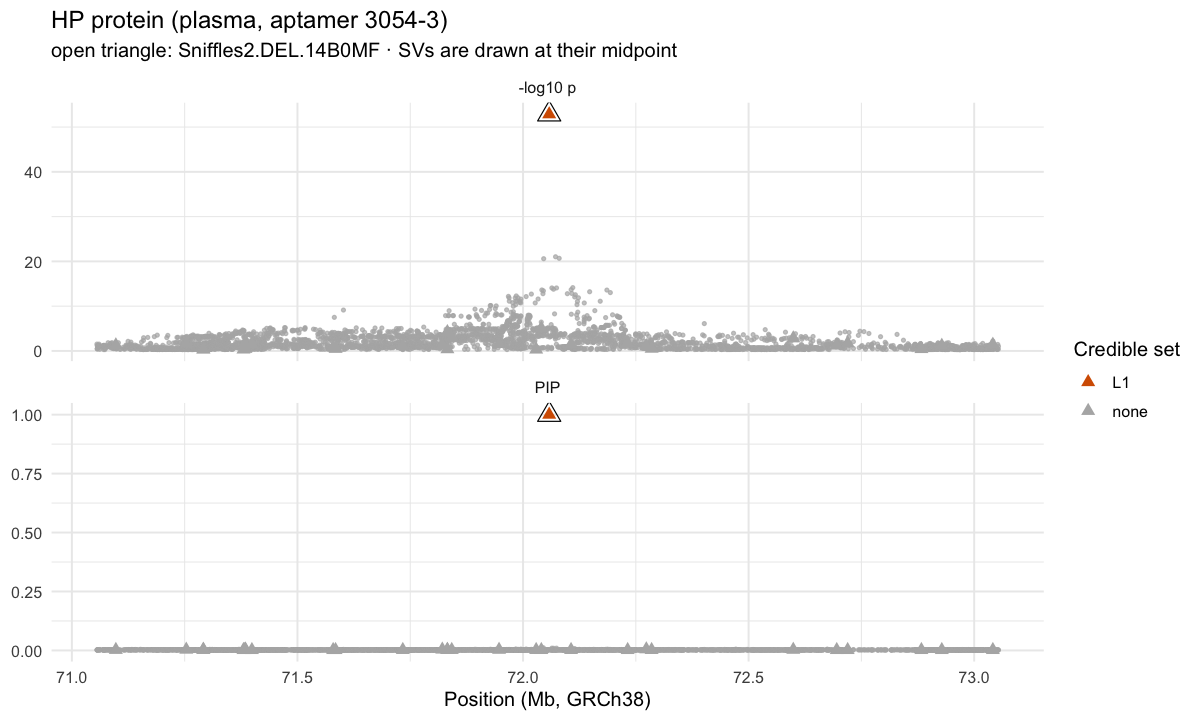

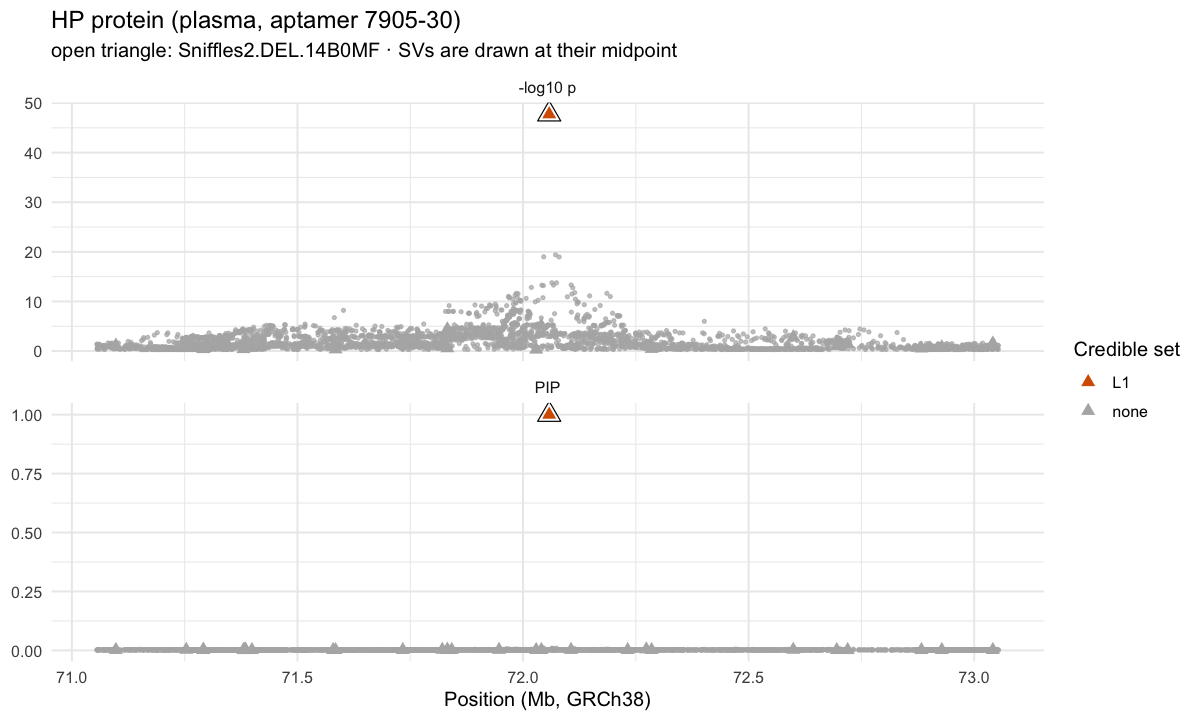

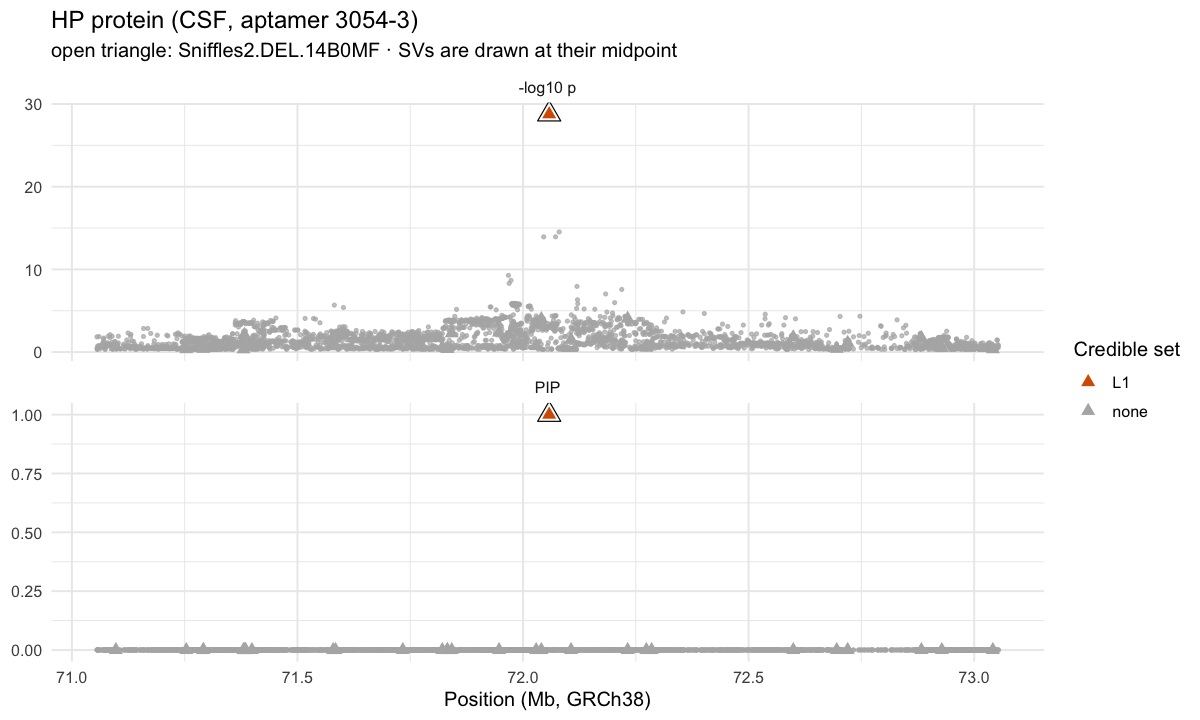

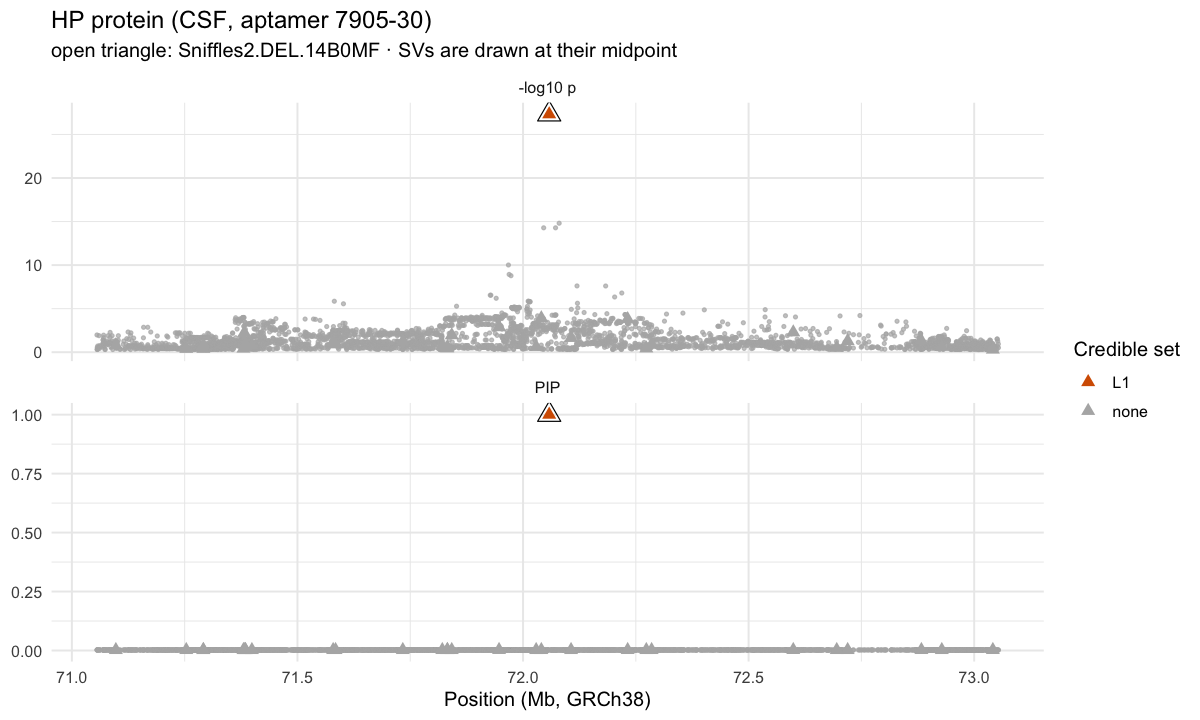

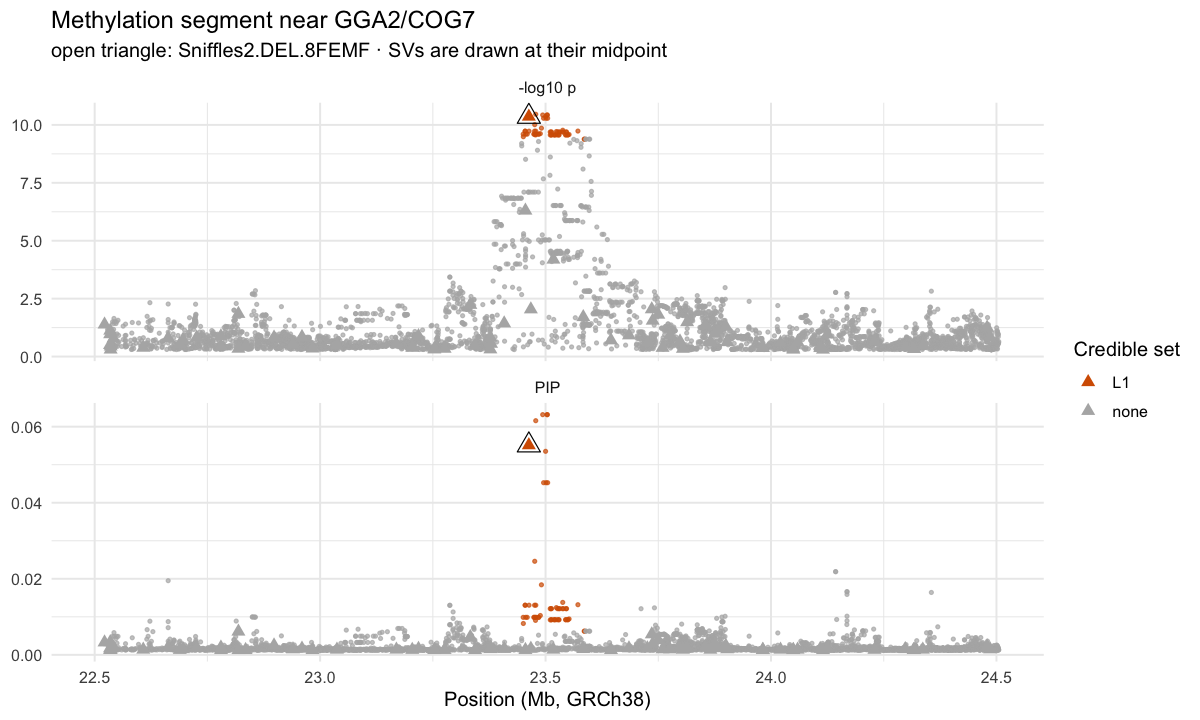

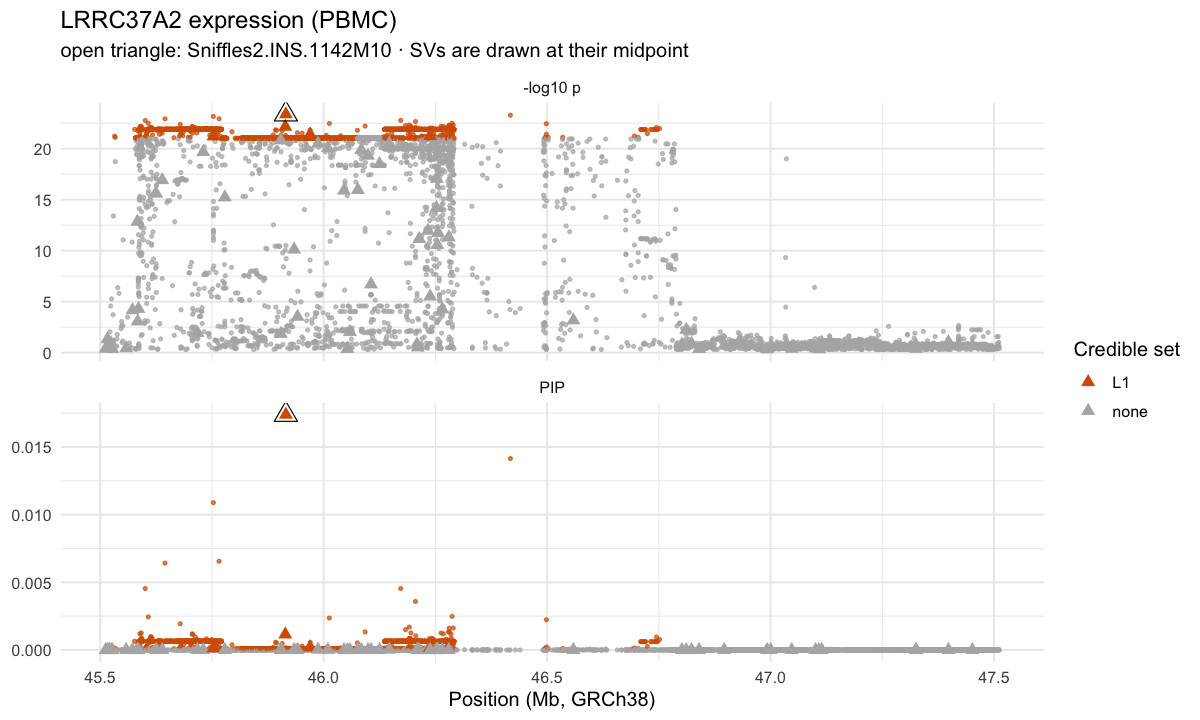

In [9]:
plot_finemap <- function(this_pheno, layer, label, highlight) {
    pos <- layers[[layer]]$info[pheno_id == this_pheno]
    xlim <- c(pos$start - CIS_WINDOW, pos$end + CIS_WINDOW) / 1e6
    v <- copy(fits[[this_pheno]]$vardata)
    v[, mb := start / 1e6]
    v[, cs := ifelse(is.na(credible_set), "none", credible_set)]
    v[, panel := "-log10 p"]
    w <- copy(v); w[, panel := "PIP"]
    d <- rbind(v[, .(mb, y = -log10(pvalue), var_type, cs, panel, var_id)],
               w[, .(mb, y = pip, var_type, cs, panel, var_id)])
    ggplot(d, aes(mb, y)) +
        geom_point(data = d[var_type == "SNP"], aes(colour = cs), size = 0.8, alpha = 0.7) +
        geom_point(data = d[var_type == "SV"], aes(colour = cs), shape = 17, size = 2.6) +
        geom_point(data = d[var_id == highlight], shape = 2, size = 4.5, colour = "black") +
        facet_wrap(~panel, ncol = 1, scales = "free_y") +
        scale_colour_manual(values = c(none = "grey70", L1 = "#D55E00", L2 = "#0072B2", L3 = "#009E73",
                                       L4 = "#CC79A7", L5 = "#E69F00", L6 = "#56B4E9", L7 = "#F0E442",
                                       L8 = "#000000", L9 = "#999999", L10 = "#882255")) +
        coord_cartesian(xlim = xlim) +
        labs(title = label, subtitle = paste("open triangle:", highlight, "· SVs are drawn at their midpoint"),
             x = "Position (Mb, GRCh38)", y = NULL, colour = "Credible set")
}
options(repr.plot.height = 6)
for (i in seq_len(nrow(traits))) print(plot_finemap(traits$pheno_id[i], traits$layer[i], traits$label[i], traits$sv_id[i]))
options(repr.plot.height = 4.5)

## Step 3 · Colocalization with AD and PD GWAS

Colocalization asks whether the trait and the disease share **one causal variant** in the region
(hypothesis H4) rather than having two different causal variants (H3).

We run `coloc.abf` with p-values and allele frequencies. The input preparation:

* QTL p-values are the marginal p-values from the fine-mapping step (same people, same covariates).
* GWAS and QTL variants are matched by position within ±500 kb of the GWAS lead.
* Allele frequencies come from 1000 Genomes; only biallelic sites with 0.01 < AF < 0.99 whose
  alleles agree with both data sets are kept.

SVs have no position match in the GWAS, so **colocalization is done on SNVs/indels**. SVs enter
the story through the fine-mapped credible set of the trait.

In [10]:
qtl_sumstats <- function(pheno_id) {
    v <- fits[[pheno_id]]$vardata
    parts <- tstrsplit(v$var_id, ":", fixed = TRUE)
    data.table(snp_pos = as.integer(round(v$start)), ref = toupper(parts[[3]]), alt = toupper(parts[[4]]),
               pvalue = v$pvalue, var_type = v$var_type)[var_type == "SNP"]
}

harmonize <- function(g, q, ref) {
    g <- copy(g)[, `:=`(alt = toupper(effect_allele), ref = toupper(non_effect_allele))]
    d <- merge(g[, .(snp_pos, ref_gwas = ref, alt_gwas = alt, pvalue_gwas = pvalue)],
               q[, .(snp_pos, ref_eqtl = ref, alt_eqtl = alt, pvalue_eqtl = pvalue)], by = "snp_pos")
    d <- d[!(duplicated(snp_pos) | duplicated(snp_pos, fromLast = TRUE))]
    v <- ref[POS %in% d$snp_pos]
    v <- v[!(duplicated(POS) | duplicated(POS, fromLast = TRUE))]
    v <- v[!grepl(",", REF) & !grepl(",", ALT)]
    v[, AF := as.numeric(AF)]
    v <- v[AF > .01 & AF < .99]
    d <- merge(d, v[, .(snp_pos = POS, REF, ALT, AF)], by = "snp_pos")
    ok <- ((d$ref_gwas == d$REF & d$alt_gwas == d$ALT) | (d$alt_gwas == d$REF & d$ref_gwas == d$ALT)) &
          ((d$ref_eqtl == d$REF & d$alt_eqtl == d$ALT) | (d$alt_eqtl == d$REF & d$ref_eqtl == d$ALT))
    d[ok][complete.cases(pvalue_gwas, pvalue_eqtl, AF)]
}

run_coloc <- function(locus, layer, pheno_id, gwas, lead) {
    g <- fread(file.path(DATA_DIR, "gwas", paste0(gwas, ".", locus, ".tsv.gz")))
    ref <- fread(file.path(DATA_DIR, "reference", paste0("1000G.", locus, ".tsv.gz")))
    lo <- lead - COLOC_HALF_WINDOW; hi <- lead + COLOC_HALF_WINDOW
    q <- qtl_sumstats(pheno_id)
    d <- harmonize(g[snp_pos >= lo & snp_pos <= hi], q[snp_pos >= lo & snp_pos <= hi], ref)
    dataset1 <- list(pvalues = d$pvalue_gwas, MAF = d$AF, s = GWAS_CASE_FRACTION, N = GWAS_N[[gwas]], type = "cc")
    dataset2 <- list(pvalues = d$pvalue_eqtl, MAF = d$AF, N = QTL_N[[layer]], type = "quant")
    dataset1$snp <- dataset2$snp <- as.character(d$snp_pos)
    res <- suppressWarnings(suppressMessages(coloc.abf(dataset1, dataset2)))
    list(summary = res$summary, data = d, results = res$results)
}

colocs <- LOCI[gwas != ""]
coloc_res <- list()
for (i in seq_len(nrow(colocs))) {
    a <- colocs[i]
    key <- paste(a$gwas, a$gwas_lead_pos, a$pheno_id)
    invisible(capture.output(r <- run_coloc(a$locus, a$layer, a$pheno_id, a$gwas, as.integer(a$gwas_lead_pos))))
    coloc_res[[key]] <- r
}
coloc_table <- rbindlist(lapply(seq_len(nrow(colocs)), function(i) {
    a <- colocs[i]; r <- coloc_res[[paste(a$gwas, a$gwas_lead_pos, a$pheno_id)]]
    data.table(trait = a$label, GWAS = a$gwas, GWAS_lead = paste0(a$chrom, ":", a$gwas_lead_pos),
               SNVs = r$summary[["nsnps"]], PP.H3 = round(r$summary[["PP.H3.abf"]], 3),
               PP.H4 = round(r$summary[["PP.H4.abf"]], 3))
}))
coloc_table

trait,GWAS,GWAS_lead,SNVs,PP.H3,PP.H4
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
Methylation segment near GGA2/COG7,AD,chr16:23466676,1830,0.382,0.578
LRRC37A2 expression (PBMC),AD,chr17:46613342,1140,0.406,0.594
LRRC37A2 expression (PBMC),AD,chr17:46720553,1006,0.146,0.854
LRRC37A2 expression (PBMC),PD,chr17:46276519,2159,0.212,0.788
LRRC37A2 expression (PBMC),PD,chr17:46783637,1116,0.013,0.987


### Colocalization plots

Two views of each test, in the style of the paper's Figure 6:

* **Regional plots**: GWAS and QTL −log10 p along the window, coloured by LD (r²) with the GWAS lead
  SNV. A dashed line marks the SV highlighted in the paper when it lies in the window.
* **LocusCompare plot**: GWAS −log10 p against QTL −log10 p for the same SNVs. When both traits share one
  causal variant, the strongest SNVs sit in the top-right corner and are in high LD with the lead.

LD is computed from the Twin SNV dosages (416 people). When the GWAS lead is not in our SNV panel, the
SNV with the smallest GWAS p-value is used as the reference instead.

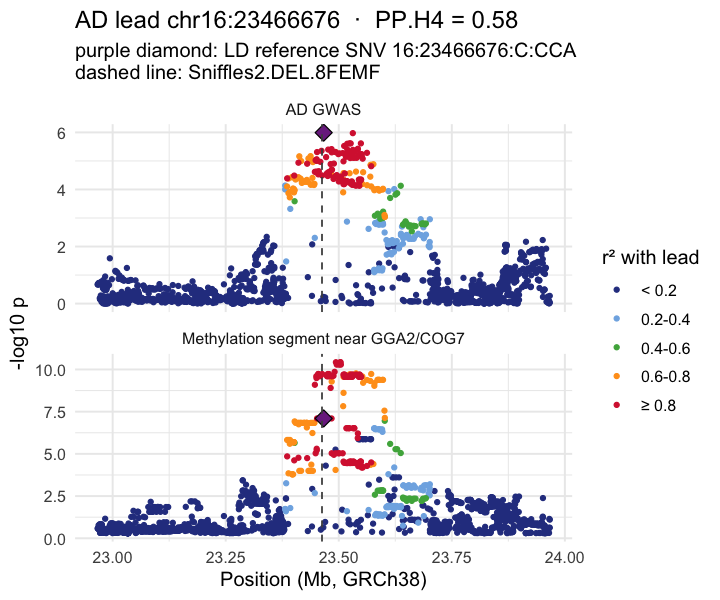

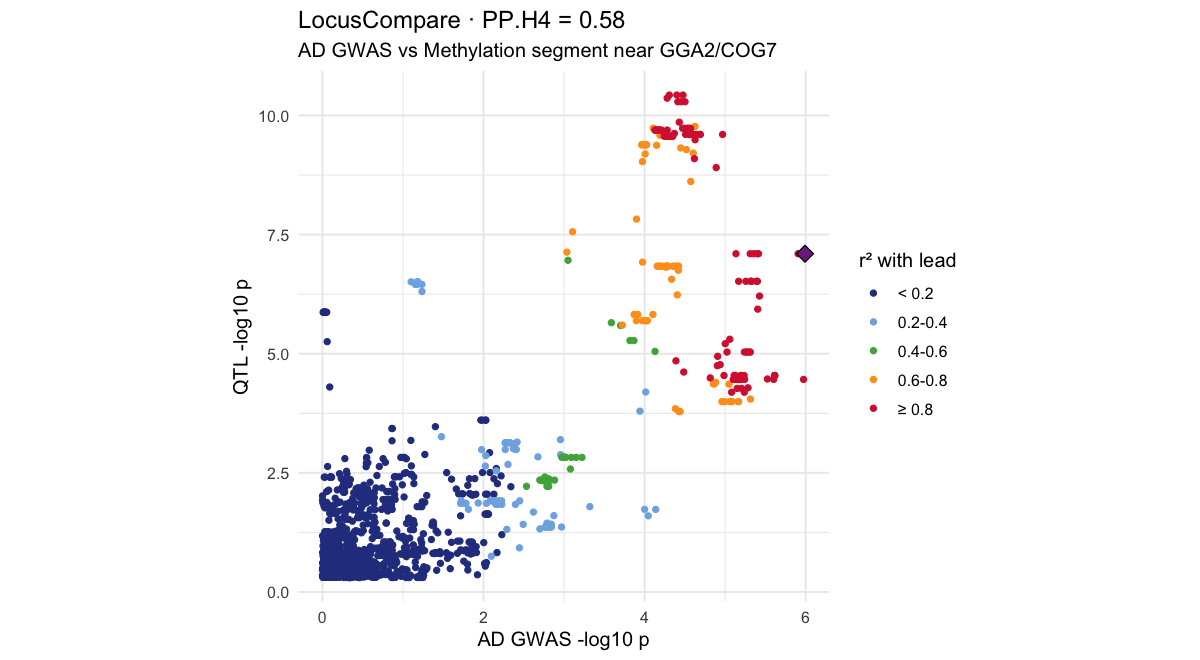

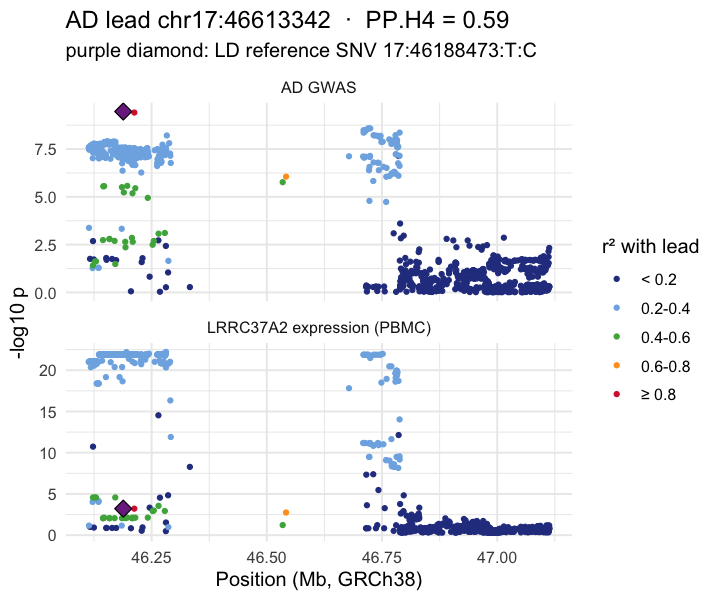

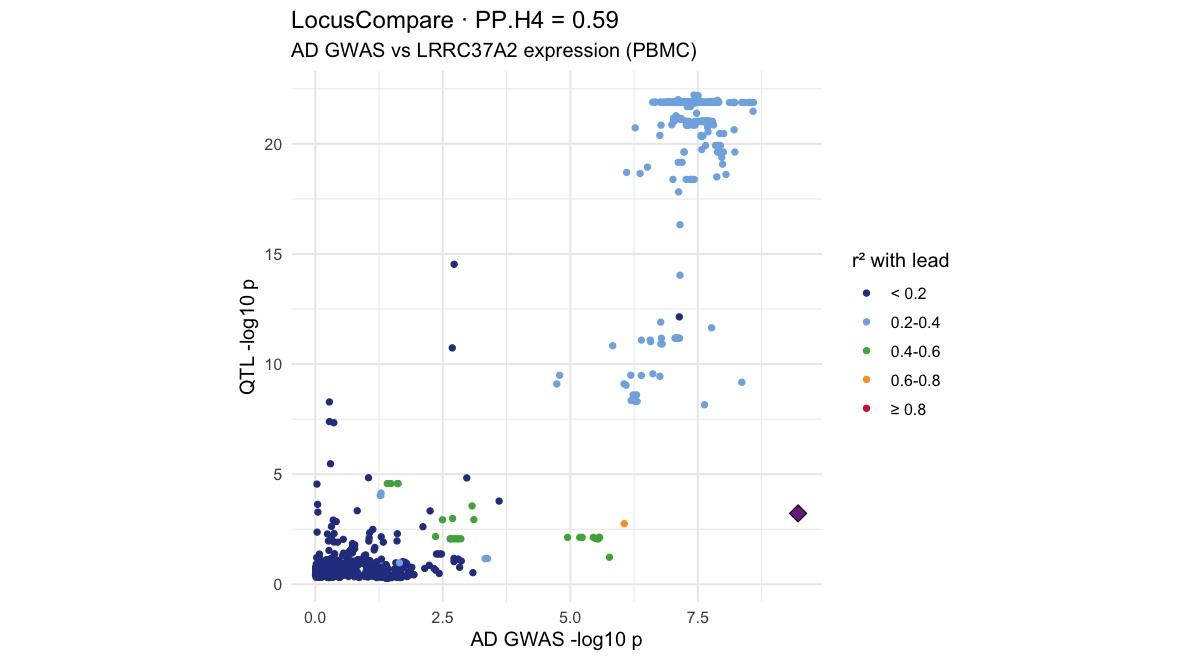

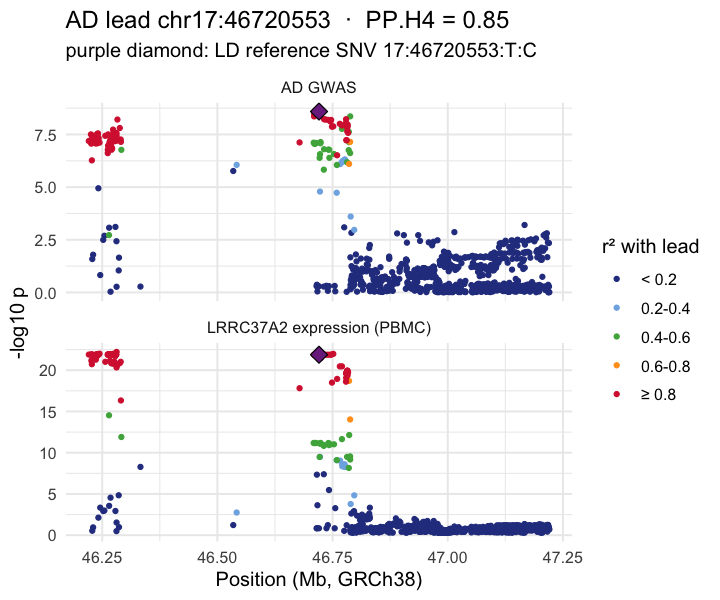

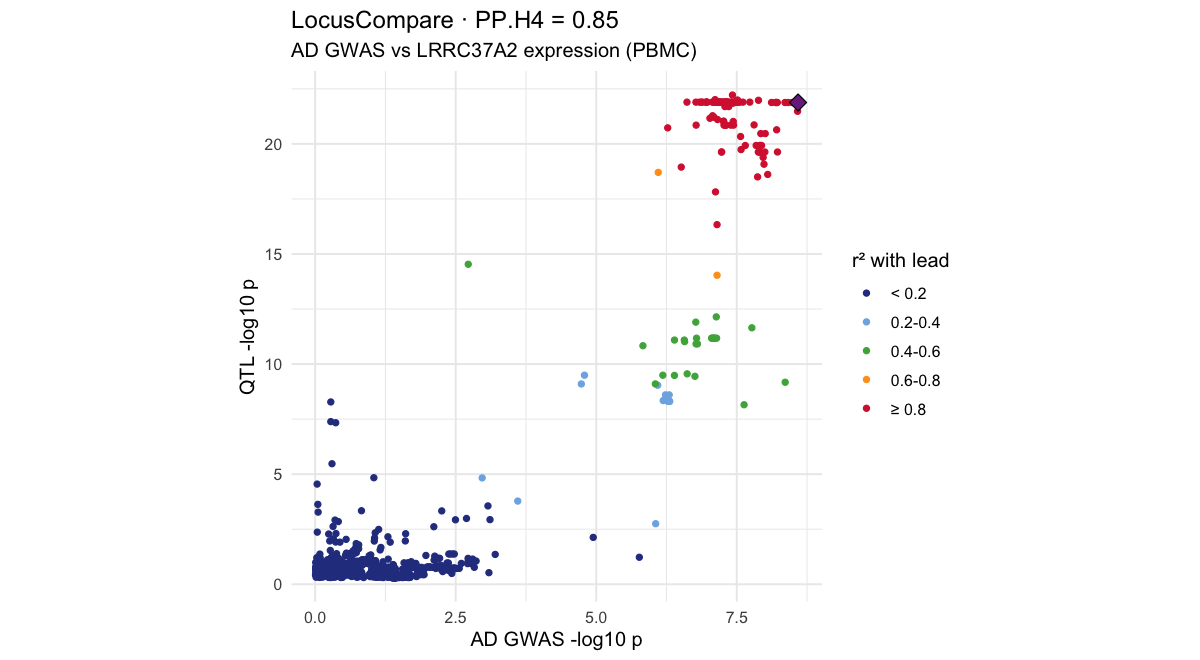

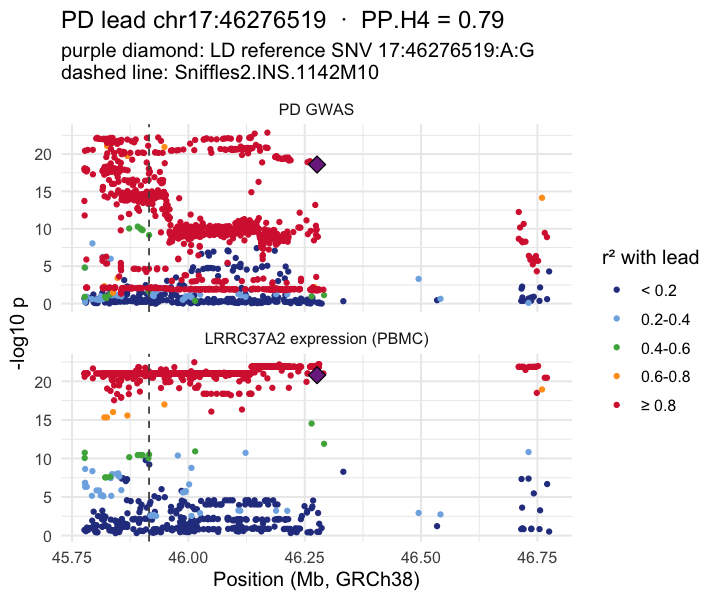

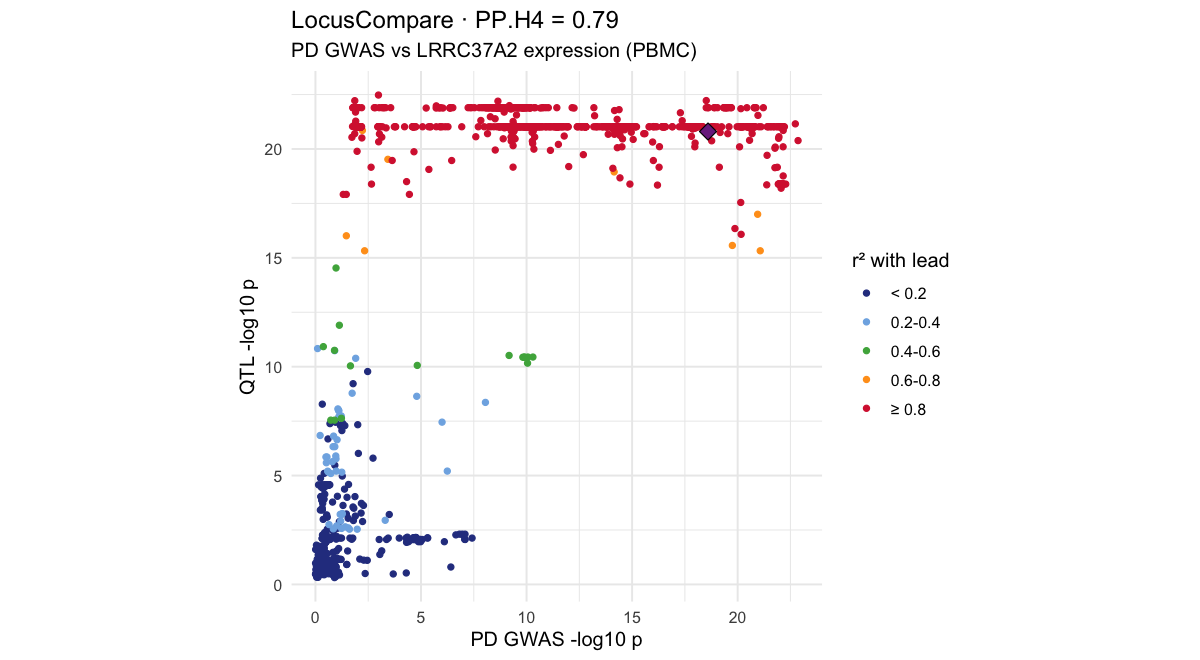

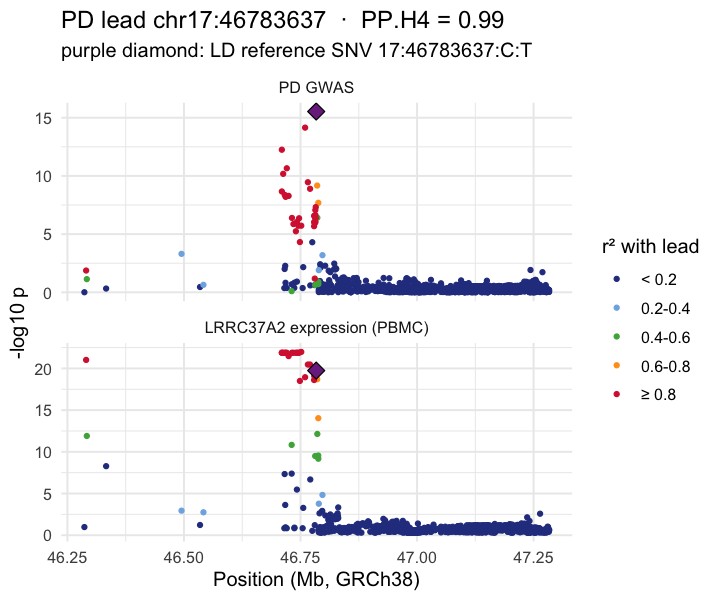

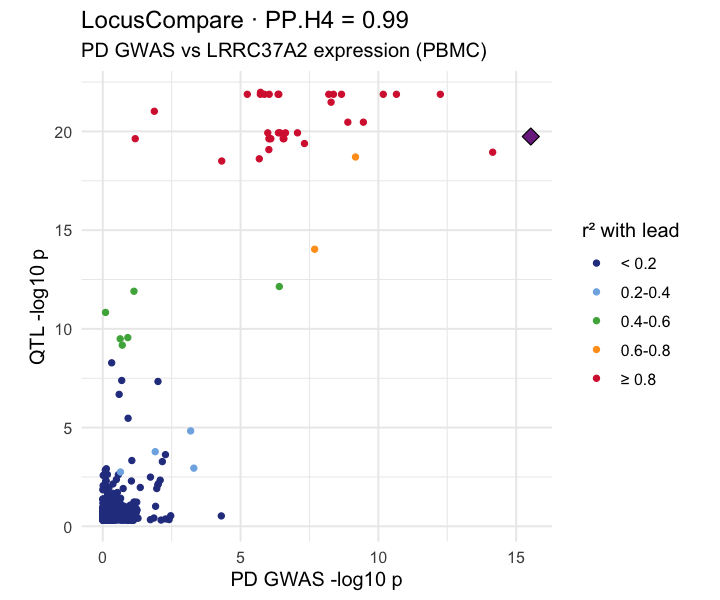

In [11]:
R2_BREAKS <- c(-Inf, 0.2, 0.4, 0.6, 0.8, Inf)
R2_LABELS <- c("< 0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "≥ 0.8")
R2_COLOURS <- c("#2C3E8F", "#7FB2E5", "#4DAF4A", "#FF9F1C", "#D7263D")

coloc_plot_data <- function(i) {
    a <- colocs[i]; r <- coloc_res[[paste(a$gwas, a$gwas_lead_pos, a$pheno_id)]]
    snv <- geno[[a$locus]]$SNV
    d <- copy(r$data)
    d[, variant_id := paste(sub("chr", "", a$chrom), snp_pos, ref_eqtl, alt_eqtl, sep = ":")]
    lead <- as.integer(a$gwas_lead_pos)
    ref_id <- if (lead %in% d$snp_pos) d[snp_pos == lead, variant_id] else d[which.min(pvalue_gwas), variant_id]
    d[, r2 := as.vector(cor(t(snv$mat[variant_id, , drop = FALSE]), snv$mat[ref_id, ])^2)]
    d[, ld := factor(as.character(cut(r2, R2_BREAKS, labels = R2_LABELS)), levels = R2_LABELS)]
    d[, is_ref := variant_id == ref_id]
    sv <- geno[[a$locus]]$SV$info[variant_id == a$sv_id]
    list(a = a, r = r, d = d[order(r2)], ref_id = ref_id, sv_mb = (sv$start + sv$end) / 2e6)
}

plot_coloc_regional <- function(x) {
    with(x, {
        long <- rbind(d[, .(mb = snp_pos / 1e6, y = -log10(pvalue_gwas), ld, is_ref, panel = paste(a$gwas, "GWAS"))],
                      d[, .(mb = snp_pos / 1e6, y = -log10(pvalue_eqtl), ld, is_ref, panel = a$label)])
        long[, panel := factor(panel, levels = c(paste(a$gwas, "GWAS"), a$label))]
        lim <- range(d$snp_pos) / 1e6
        p <- ggplot(long, aes(mb, y)) +
            geom_point(aes(colour = ld), size = 1.1) +
            geom_point(data = long[is_ref == TRUE], shape = 23, size = 3.5, fill = "#7B2D8E", colour = "black") +
            facet_wrap(~panel, ncol = 1, scales = "free_y") +
            scale_colour_manual(values = setNames(R2_COLOURS, R2_LABELS), drop = FALSE) +
            labs(title = sprintf("%s lead %s:%s  ·  PP.H4 = %.2f", a$gwas, a$chrom, a$gwas_lead_pos, r$summary[["PP.H4.abf"]]),
                 subtitle = paste("purple diamond: LD reference SNV", ref_id),
                 x = "Position (Mb, GRCh38)", y = "-log10 p", colour = "r² with lead")
        if (sv_mb >= lim[1] && sv_mb <= lim[2])
            p <- p + geom_vline(xintercept = sv_mb, linetype = 2, colour = "grey30") +
                labs(subtitle = paste0("purple diamond: LD reference SNV ", ref_id, "\ndashed line: ", a$sv_id))
        p
    })
}

plot_locuscompare <- function(x) {
    with(x, ggplot(d, aes(-log10(pvalue_gwas), -log10(pvalue_eqtl))) +
        geom_point(aes(colour = ld), size = 1.4) +
        geom_point(data = d[is_ref == TRUE], shape = 23, size = 3.5, fill = "#7B2D8E", colour = "black") +
        scale_colour_manual(values = setNames(R2_COLOURS, R2_LABELS), drop = FALSE) +
        labs(title = sprintf("LocusCompare · PP.H4 = %.2f", r$summary[["PP.H4.abf"]]),
             subtitle = paste(a$gwas, "GWAS vs", a$label),
             x = paste(a$gwas, "GWAS -log10 p"), y = "QTL -log10 p", colour = "r² with lead") +
        theme(aspect.ratio = 1))
}

for (i in seq_len(nrow(colocs))) {
    x <- coloc_plot_data(i)
    options(repr.plot.width = 10, repr.plot.height = 5.5); print(plot_coloc_regional(x))
    options(repr.plot.width = 6, repr.plot.height = 5); print(plot_locuscompare(x))
}
options(repr.plot.width = 10, repr.plot.height = 4.5)

## Step 4 · Put it together

The paper reports an SV as a candidate disease variant when the trait colocalizes with the GWAS
(PP.H4 > 0.5) **and** the SV is in one of the trait's credible sets (Extended Data Table 2).

In [12]:
summary_table <- merge(
    coloc_table,
    paper_sv[, .(trait, SV, SV_pip, SV_credible_set)], by = "trait")
summary_table[, colocalizes := PP.H4 > 0.5]
summary_table[, SV_in_credible_set := !is.na(SV_credible_set)]
summary_table

trait,GWAS,GWAS_lead,SNVs,PP.H3,PP.H4,SV,SV_pip,SV_credible_set,colocalizes,SV_in_credible_set
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<lgl>,<lgl>
LRRC37A2 expression (PBMC),AD,chr17:46613342,1140,0.406,0.594,Sniffles2.INS.1142M10,0.0174,L1,TRUE,TRUE
LRRC37A2 expression (PBMC),AD,chr17:46720553,1006,0.146,0.854,Sniffles2.INS.1142M10,0.0174,L1,TRUE,TRUE
LRRC37A2 expression (PBMC),PD,chr17:46276519,2159,0.212,0.788,Sniffles2.INS.1142M10,0.0174,L1,TRUE,TRUE
LRRC37A2 expression (PBMC),PD,chr17:46783637,1116,0.013,0.987,Sniffles2.INS.1142M10,0.0174,L1,TRUE,TRUE
Methylation segment near GGA2/COG7,AD,chr16:23466676,1830,0.382,0.578,Sniffles2.DEL.8FEMF,0.0551,L1,TRUE,TRUE


### What the paper reports, for comparison

* **HP**: the 1.7 kb deletion is the lead variant for HP protein levels and sits alone in its credible set.
* **GGA2 / COG7**: the methylation segment colocalizes with AD and the 208 bp tandem-repeat deletion near the
  COG7 promoter is in its credible set (Extended Data Table 2; the paper does not give the PP.H4).
* **LRRC37A2**: expression colocalizes with AD (PP.H4 = 0.79 at lead chr17:46,720,553) and PD (PP.H4 = 0.98
  at lead chr17:46,783,637), with a 37 bp insertion as the lead variant of the credible set.

Numbers differ slightly from the paper because the Twin is not the original data.

## Questions

1. At COG7 the deletion is in the credible set but its PIP is small, and PP.H4 is only a little above 0.5.
   What does "in the credible set" mean, and what does it *not* mean? How confident are you in this locus?
2. Why is the MAPT credible set so much larger than the HP one? (Hint: compare the purity column and
   think about the inversion haplotype.)
3. Colocalization used SNVs only. How would you argue that the SV, and not a nearby SNV, is the shared
   causal variant?
4. Run the cell below, which fine-maps LRRC37A2 with `L = 1` (one causal signal only). Does the credible
   set change? Why or why not?

In [13]:
f1 <- finemap_pheno("MAPT", "RNA", "ENSG00000238083:LRRC37A2", L = 1)
cs_summary(f1, "LRRC37A2 expression, L = 1")

trait,cs,size,purity,lead_variant,lead_pip,SVs_in_cs,SV_is_lead
<chr>,<chr>,<int>,<dbl>,<chr>,<dbl>,<chr>,<lgl>
"LRRC37A2 expression, L = 1",L1,2656,0.885,Sniffles2.INS.1142M10,0.017,Sniffles2.DEL.113AM10; Sniffles2.INS.1141M10; Sniffles2.INS.1142M10; Sniffles2.DEL.1149M10; Sniffles2.DEL.116FM10,TRUE
